# 01 – EDA: LinkedIn job postings

Goal: decide the project scope with numbers.

1. How many data / AI postings are there?
2. How many of them have a salary?
3. How are salaries spread across states?
4. How many postings per role?
5. How long are the job descriptions?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

DATA_DIR = "../data/raw/linkedin"
postings = pd.read_csv(f"{DATA_DIR}/postings.csv")
postings.shape

(123849, 31)

In [2]:
postings.info()

<class 'pandas.DataFrame'>
RangeIndex: 123849 entries, 0 to 123848
Data columns (total 31 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   job_id                      123849 non-null  int64  
 1   company_name                122130 non-null  str    
 2   title                       123849 non-null  str    
 3   description                 123842 non-null  str    
 4   max_salary                  29793 non-null   float64
 5   pay_period                  36073 non-null   str    
 6   location                    123849 non-null  str    
 7   company_id                  122132 non-null  float64
 8   views                       122160 non-null  float64
 9   med_salary                  6280 non-null    float64
 10  min_salary                  29793 non-null   float64
 11  formatted_work_type         123849 non-null  str    
 12  applies                     23320 non-null   float64
 13  original_listed_time     

In [3]:
missing = postings.isna().mean().sort_values(ascending=False)
missing.round(3)

closed_time                   0.991
skills_desc                   0.980
med_salary                    0.949
remote_allowed                0.877
applies                       0.812
max_salary                    0.759
min_salary                    0.759
currency                      0.709
compensation_type             0.709
normalized_salary             0.709
pay_period                    0.709
posting_domain                0.323
application_url               0.296
formatted_experience_level    0.237
fips                          0.221
zip_code                      0.169
company_name                  0.014
company_id                    0.014
views                         0.014
description                   0.000
work_type                     0.000
sponsored                     0.000
job_id                        0.000
listed_time                   0.000
expiry                        0.000
application_type              0.000
original_listed_time          0.000
formatted_work_type         

In [4]:
salary_cols = ["min_salary", "med_salary", "max_salary", "pay_period",
               "currency", "compensation_type", "normalized_salary"]
postings[salary_cols].sample(10, random_state=42)

,min_salary,med_salary,max_salary,pay_period,currency,compensation_type,normalized_salary
73989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59308,19.75,NaN,19.75,HOURLY,USD,BASE_SALARY,41080.0
44663,NaN,NaN,NaN,NaN,NaN,NaN,NaN
81954,NaN,NaN,NaN,NaN,NaN,NaN,NaN
113151,30.00,NaN,35.00,HOURLY,USD,BASE_SALARY,67600.0
60072,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50425,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75853,35.00,NaN,40.00,HOURLY,USD,BASE_SALARY,78000.0
72947,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58062,NaN,72.0,NaN,HOURLY,USD,BASE_SALARY,149760.0


In [5]:
print(postings["pay_period"].value_counts(dropna=False))
print(postings["currency"].value_counts(dropna=False))
print(postings["remote_allowed"].value_counts(dropna=False))

pay_period
NaN         87776
YEARLY      20628
HOURLY      14741
MONTHLY       518
WEEKLY        177
BIWEEKLY        9
Name: count, dtype: int64
currency
NaN    87776
USD    36058
EUR        6
CAD        3
BBD        2
AUD        2
GBP        2
Name: count, dtype: int64
remote_allowed
NaN    108603
1.0     15246
Name: count, dtype: int64


In [6]:
postings.groupby("pay_period")["normalized_salary"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
pay_period,,,,,,,,
BIWEEKLY,9.0,1248662.0,908696.0,53482.0,72943.0,1572805.0,1897389.0,2096744.0
HOURLY,14741.0,330624.0,7927651.0,14560.0,40622.0,52520.0,86320.0,535600000.0
MONTHLY,518.0,64083.0,74190.0,420.0,28347.0,53634.0,82109.0,1200000.0
WEEKLY,177.0,111560.0,21382.0,50804.0,99684.0,109148.0,119658.0,210548.0
YEARLY,20628.0,119685.0,715898.0,0.0,72500.0,102000.0,142500.0,102500000.0


In [7]:
sal = postings[postings["normalized_salary"].notna()].copy()
print("with salary:", len(sal))

sal = sal[(sal["currency"] == "USD") & (sal["pay_period"] != "BIWEEKLY")]
print("USD, no BIWEEKLY:", len(sal))

LOW, HIGH = 20_000, 600_000
outliers = sal[(sal["normalized_salary"] < LOW) | (sal["normalized_salary"] > HIGH)]
print("outside range:", len(outliers))

cols = ["title", "pay_period", "min_salary", "med_salary", "max_salary", "normalized_salary"]
outliers[cols].sort_values("normalized_salary").head(10)

with salary: 36073
USD, no BIWEEKLY: 36049
outside range: 534


,title,pay_period,min_salary,med_salary,max_salary,normalized_salary
71180,Community Manager,YEARLY,NaN,0.0,NaN,0.0
8305,Full-Stack Engineer Intern (Unpaid),YEARLY,NaN,0.0,NaN,0.0
17594,Sales Consultant (B2B),YEARLY,NaN,0.0,NaN,0.0
6395,Independent Sales Representative,YEARLY,NaN,0.0,NaN,0.0
62013,Public Health Empowerment Pro Bono Coach,YEARLY,NaN,0.0,NaN,0.0
46750,UX/UI Designer,YEARLY,NaN,0.0,NaN,0.0
62083,Ikigai-Inspired Coach – CrowdDoing Pro Bono Coaching Collective,YEARLY,NaN,0.0,NaN,0.0
25681,Marketing Specialist,YEARLY,NaN,0.0,NaN,0.0
60721,"Volunteer Scrum Master – Driving Nature Connection and Public Health, CrowdDoing.world's Nature ...",YEARLY,NaN,0.0,NaN,0.0
62061,Environmental Stewardship Pro Bono Coach,YEARLY,NaN,0.0,NaN,0.0


In [8]:
outliers[cols].sort_values("normalized_salary").tail(10)

,title,pay_period,min_salary,med_salary,max_salary,normalized_salary
87241,Full Time Field Service Technician – Anaheim/Pomona Area,HOURLY,62000.0,NaN,68000.0,135200000.0
17646,DCS Technician,HOURLY,70000.0,NaN,80000.0,156000000.0
72585,Trial Paralegal - Hybrid in OC or LA!,HOURLY,80000.0,NaN,100000.0,187200000.0
71845,Sharepoint Developer,HOURLY,100000.0,NaN,120000.0,228800000.0
102481,Manager - Clinical Applications Support - Ancillary Systems,HOURLY,98467.0,NaN,123094.0,230423440.0
60038,Billing Supervisor (246521),HOURLY,125000.0,NaN,125000.0,260000000.0
13614,Cloud Domain Architect,HOURLY,125000.0,NaN,150000.0,286000000.0
89082,Cloud Domain Architect,HOURLY,125000.0,NaN,150000.0,286000000.0
98888,"Case Manager RN, Pedi Rheumatology",HOURLY,151900.0,NaN,196570.0,362408800.0
9237,Intellectual Property Associate (246215),HOURLY,240000.0,NaN,275000.0,535600000.0


In [9]:
sal["raw_mid"] = sal["med_salary"].fillna((sal["min_salary"] + sal["max_salary"]) / 2)

wrong_hourly = (sal["pay_period"] == "HOURLY") & (sal["raw_mid"] >= 1_000)
print("hourly that look yearly:", wrong_hourly.sum())

sal.loc[wrong_hourly, "normalized_salary"] = sal.loc[wrong_hourly, "raw_mid"]
sal.loc[wrong_hourly, "pay_period"] = "YEARLY"
sal["salary_fixed"] = wrong_hourly

out = (sal["normalized_salary"] < LOW) | (sal["normalized_salary"] > HIGH)
print("still outside range:", out.sum())
sal[out].groupby("pay_period")["normalized_salary"].describe().round(0)

hourly that look yearly: 29
still outside range: 511


,count,mean,std,min,25%,50%,75%,max
pay_period,,,,,,,,
HOURLY,8.0,246436.0,457118.0,14560.0,15938.0,17451.0,170040.0,1248000.0
MONTHLY,28.0,86420.0,282569.0,420.0,6450.0,12000.0,13500.0,1200000.0
YEARLY,475.0,258373.0,4704259.0,0.0,26.0,52.0,125.0,102500000.0


In [10]:
wrong_yearly = (sal["pay_period"] == "YEARLY") & sal["raw_mid"].between(10, 200)
print("yearly that look hourly:", wrong_yearly.sum())

sal.loc[wrong_yearly, "normalized_salary"] = sal.loc[wrong_yearly, "raw_mid"] * 2080
sal.loc[wrong_yearly, "pay_period"] = "HOURLY"
sal["salary_fixed"] = sal["salary_fixed"] | wrong_yearly

out = (sal["normalized_salary"] < LOW) | (sal["normalized_salary"] > HIGH)
print("dropped:", out.sum())
sal = sal[~out].copy()

print("clean salary rows:", len(sal))
print("fixed rows:", sal["salary_fixed"].sum())
sal["normalized_salary"].describe().round(0)

yearly that look hourly: 372
dropped: 139
clean salary rows: 35910
fixed rows: 395


count     35910.0
mean      96398.0
std       58275.0
min       20000.0
25%       52260.0
50%       82500.0
75%      125000.0
max      600000.0
Name: normalized_salary, dtype: float64

### Salary cleaning rules

- Keep only USD, drop BIWEEKLY (9 rows, broken values).
- HOURLY with raw value >= 1,000 → really yearly, use raw value.
- YEARLY with raw value between 10 and 200 → really hourly, multiply by 2,080.
- Drop everything still outside 20,000 – 600,000 USD per year.
- `salary_fixed` marks every repaired row.

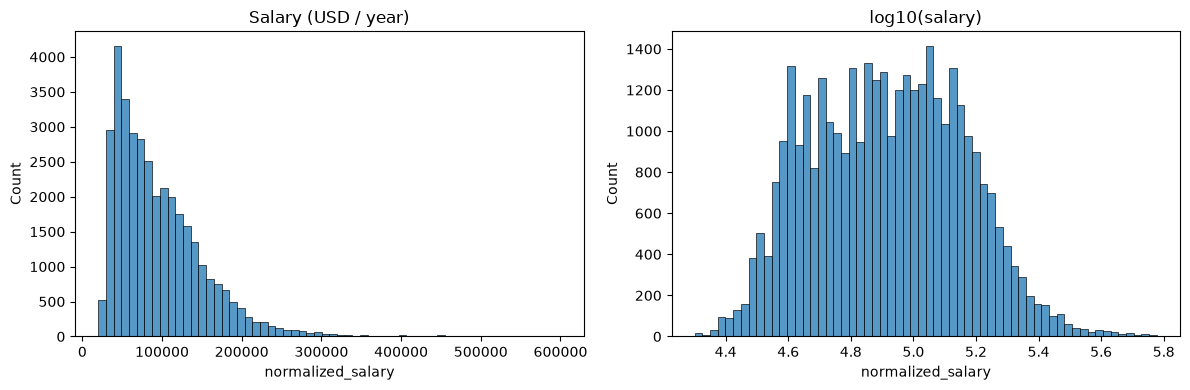

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(sal["normalized_salary"], bins=60, ax=axes[0])
axes[0].set_title("Salary (USD / year)")

sns.histplot(np.log10(sal["normalized_salary"]), bins=60, ax=axes[1])
axes[1].set_title("log10(salary)")

plt.tight_layout()
plt.show()

**Finding:** salary is right-skewed (median 82.5k < mean 96.4k). log(salary) is roughly symmetric → the salary model will predict log(salary).

In [12]:
pattern = (r"\bdata\b|machine learning|\bml\b|\bai\b|artificial intelligence|"
           r"analytics|\bbi\b|business intelligence|deep learning|\bnlp\b|"
           r"computer vision|\bllm\b|mlops")

is_data = postings["title"].str.contains(pattern, case=False, regex=True, na=False)
data_jobs = postings[is_data].copy()
print("data / AI postings:", len(data_jobs))

data_jobs["title"].str.lower().value_counts().head(40)

data / AI postings: 3274


title
data analyst                                                                               137
data engineer                                                                               90
data scientist                                                                              56
senior data engineer                                                                        44
data architect                                                                              27
senior data analyst                                                                         25
machine learning engineer                                                                   23
data modeler                                                                                21
senior data scientist                                                                       21
data entry specialist                                                                       20
online data analyst                         

In [13]:
data_jobs["title"].sample(30, random_state=0).tolist()

['Data Warehouse Engineer – Hybrid@ CO/ MN. ',
 'Product Owner, Experian Data Quality (US Remote)',
 'Lead Data Scientist',
 'Senior Data Scientist',
 'Data Analyst/Workstation Support',
 'Vice President of Sales - Key Data Center Logos - Remote (Travelled Required)',
 'Marketing Business Intelligence Manager',
 'Data Scientist Intern (Monetization Product and Technology-Strategy and Data Science-Global Data Science-Performance Ads ) - 2024 Off-Cycle (BS/MS)',
 'Data Scientist III',
 'Business Intelligence Developer',
 'Data Science Manager',
 'QA Tester with Power BI ',
 'Data Center Operations Manager-Houston Texas',
 'Lead Developer (AI)',
 'Financial Data Analyst',
 'Senior Software Engineer - Data Platforms (US)',
 'Data Engineer',
 'Data Analyst, Marketing',
 'Data Team Lead',
 'Data Analysis, Risk Adjustment Coding',
 'Business Intelligence Lead',
 'Gas Processing AI Engineer-Relocate to Saudi Arabia, Permanent Expat Family Relocation Package',
 'Data Engineer',
 'Enterprise Dat

In [14]:
exclude = (r"data\s+entry|data\s+center|datacenter|content\s+writer|"
           r"data\s+contributor|annotat|risk\s+adjustment|"
           r"data\s+(?:collector|processor|coordinator)")

false_pos = data_jobs["title"].str.contains(exclude, case=False, regex=True, na=False)
gig_company = data_jobs["company_name"].isin(["DataAnnotation"])  # AI chatbot training gigs
print("excluded by title:", false_pos.sum(), "| by company:", (gig_company & ~false_pos).sum())

data_jobs = data_jobs[~(false_pos | gig_company)].copy()
print("data / AI postings:", len(data_jobs))

data_sal = sal[sal["job_id"].isin(data_jobs["job_id"])]
print("with clean salary:", len(data_sal))
print(data_sal["pay_period"].value_counts())
data_sal["normalized_salary"].describe().round(0)

excluded by title: 362 | by company: 38
data / AI postings: 2874
with clean salary: 958
pay_period
YEARLY     717
HOURLY     232
MONTHLY      9
Name: count, dtype: int64


count       958.0
mean     144527.0
std       57911.0
min       29120.0
25%      105010.0
50%      137500.0
75%      175494.0
max      500000.0
Name: normalized_salary, dtype: float64

### Q1 + Q2 results

- 2,874 data / AI postings (2.3% of all) after removing 362 false-positive titles (normalized: lowercase, single spaces) and 38 DataAnnotation gig postings.
- Only 958 of them have a clean salary. Median 137.5k vs 82.5k for all jobs.
- 958 rows is thin for a salary model → train on all 35,910 salary rows with role as a feature, evaluate on data jobs.

In [15]:
import sys
sys.path.append("..")
from src.roles import role_family

data_sal = data_sal.copy()
data_sal["role"] = data_sal["title"].apply(role_family)
data_sal.groupby("role")["normalized_salary"].agg(["count", "median"]).round(0)

,count,median
role,,
BI Analyst,82,122162.0
Data Analyst,245,110240.0
Data Engineer,225,143900.0
Data Manager,47,131040.0
Data Scientist,113,162200.0
ML/AI Engineer,121,182000.0
Other,125,113250.0


In [16]:
STATE_RE = r",\s*([A-Z]{2})\b"
data_sal["state"] = data_sal["location"].str.extract(STATE_RE)[0]
print("no state:", data_sal["state"].isna().sum())
data_sal["state"].value_counts(normalize=True).head(10).round(3)

no state: 268


state
CA    0.243
NY    0.120
WA    0.081
TX    0.064
VA    0.058
NJ    0.046
FL    0.045
NC    0.030
OH    0.030
GA    0.028
Name: proportion, dtype: float64

### Selection bias between the two datasets

- LinkedIn data salaries: 44% from CA, NY, WA (pay transparency laws, high-cost markets).
- Google search salaries: 71% have no state; of the rest, 87% from MO, OK, CO, KS, AR.
- This explains why gsearch is 13–20% lower within the same role.
- Decision: MVP salary model on LinkedIn (35,910 rows, state as feature). Add gsearch later only if it lowers test error on LinkedIn data jobs.

In [17]:
import importlib
import src.roles
importlib.reload(src.roles)
from src.roles import seniority_from_title

data_sal["seniority"] = data_sal["title"].apply(seniority_from_title)

print(data_sal["formatted_experience_level"].value_counts(dropna=False))
pd.crosstab(data_sal["seniority"], data_sal["formatted_experience_level"].fillna("missing"))

formatted_experience_level
Mid-Senior level    479
NaN                 192
Entry level         141
Associate            73
Director             49
Executive            12
Internship           12
Name: count, dtype: int64


formatted_experience_level,Associate,Director,Entry level,Executive,Internship,Mid-Senior level,missing
seniority,,,,,,,
Intern,0,0,3,0,11,0,4
Junior,1,0,7,0,0,2,1
Lead/Principal,6,40,12,2,0,135,44
Not stated,58,7,113,10,1,214,108
Senior,8,2,6,0,0,128,35


In [18]:
importlib.reload(src.roles)
from src.roles import combine_seniority

data_sal["level"] = [combine_seniority(t, l) for t, l in
                     zip(data_sal["seniority"], data_sal["formatted_experience_level"])]

(data_sal.groupby("level")["normalized_salary"]
         .agg(["count", "median"])
         .sort_values("median")
         .round(0))

,count,median
level,,
Intern,19,57200.0
Junior,182,101000.0
Mid-Senior,214,131258.0
Unknown,108,137750.0
Senior,177,140400.0
Lead/Principal,197,162500.0
Director+,61,218000.0


### Seniority feature

- Combined title keywords (precise) with LinkedIn's formatted_experience_level (more coverage).
- Title patterns fixed: "intern" no longer matches internal / international; "staff" only means senior for staff engineers / scientists (not staff accountant or staff nurse).
- Median salary rises monotonically: Intern 57.2k → Junior 101k → Mid-Senior 131k → Senior 140k → Lead/Principal 162.5k → Director+ 218k.
- Intern (19) and Director+ (61) are thin for data jobs alone → another reason for the pooled model.

## Q3: Feature coverage on all 35,910 salary rows (state + seniority)

In [19]:
sal["state"] = sal["location"].str.extract(STATE_RE)[0]
sal["seniority"] = sal["title"].apply(seniority_from_title)
sal["level"] = [combine_seniority(t, l) for t, l in
                zip(sal["seniority"], sal["formatted_experience_level"])]

print("no state share:", round(sal["state"].isna().mean(), 3))
state_counts = sal["state"].value_counts()
print("states:", state_counts.size)
print("states with < 100 rows:", (state_counts < 100).sum())
print(state_counts.tail(10))
print(sal["level"].value_counts())

no state share: 0.173
states: 51
states with < 100 rows: 13
state
MT    67
MS    65
RI    61
ND    61
DE    58
AK    47
SD    47
VT    43
WV    40
WY    27
Name: count, dtype: int64
level
Junior            11793
Lead/Principal     7174
Mid-Senior         6387
Unknown            5486
Senior             2911
Director+          1642
Intern              517
Name: count, dtype: int64


### Q3 results: feature coverage (35,910 rows)

- State: all 50 states + DC. 13 states have < 100 rows (min WY 27) → keep as is, CatBoost shrinks rare categories toward the global mean.
- 17.3% without state (US-wide / remote) → own category, not dropped.
- Seniority: every level has enough rows in the pooled data (Intern 517, Director+ 1,642).
- Idea for phase 2: add BEA Regional Price Parities as a numeric cost-of-living feature.

In [20]:
data_jobs["role"] = data_jobs["title"].apply(role_family)
print(data_jobs["role"].value_counts())

data_jobs.loc[data_jobs["role"] == "Other", "title"].str.lower().value_counts().head(30)

role
Data Engineer     712
Data Analyst      699
ML/AI Engineer    399
Data Scientist    335
Other             333
BI Analyst        242
Data Manager      154
Name: count, dtype: int64


title
director, technical program management - card data tech                   7
data specialist                                                           5
project manager, product data operations                                  4
product manager, enterprise data                                          3
manager, product management (finance data experience)                     3
senior manager, clinical data and reporting standards (remote)            3
product manager - data products                                           3
ai prompt creator                                                         3
senior associate, product manager, data ethics & privacy                  2
principal data risk associate                                             2
quality data payer specialist - rensselaer - ft/day                       2
principal product manager, authentication & data                          2
artificial intelligence vice president                                    2
data p

### Q4 results: postings per role

Data Analyst 699, Data Engineer 712, ML/AI Engineer 399, Data Scientist 335, BI Analyst 242, Data Manager 154, Other 333 (12%).
"AI" in a title only counts as ML/AI Engineer together with a technical word (engineer, developer, scientist, architect, research); AI sales, product, legal and tutor roles go to Other.
Remaining "Other" titles are mostly product management, data privacy / compliance, business and admin roles → stopped refining (80/20).

Later (NLP phase): assign remaining "Other" titles with embedding similarity to role descriptions (zero-shot), regex stays as the precise first pass.

## Q5: How long are the job descriptions?

In [21]:
from tokenizers import Tokenizer

tok = Tokenizer.from_pretrained("sentence-transformers/all-MiniLM-L6-v2")
tok.no_truncation()
tok.no_padding()

desc = data_jobs["description"].fillna("")
enc = tok.encode_batch(desc.tolist())

data_jobs["n_tokens"] = [len(e.ids) for e in enc]
data_jobs["n_words"] = desc.str.split().str.len()

print(data_jobs[["n_words", "n_tokens"]].describe().round(0))
print("share over 256 tokens:", round((data_jobs["n_tokens"] > 256).mean(), 3))
print("median share of text the model sees:",
      round((256 / data_jobs["n_tokens"]).clip(upper=1).median(), 2))

       n_words  n_tokens
count   2874.0    2874.0
mean     565.0     761.0
std      352.0     457.0
min        4.0      15.0
25%      275.0     381.0
50%      524.0     713.0
75%      794.0    1057.0
max     2486.0    3259.0
share over 256 tokens: 0.868
median share of text the model sees: 0.36


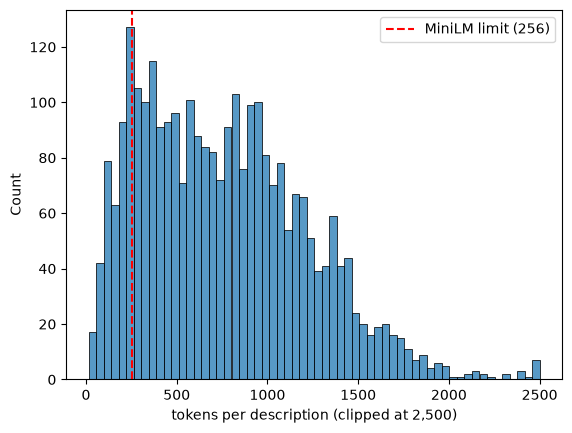

In [22]:
ax = sns.histplot(data_jobs["n_tokens"].clip(upper=2500), bins=60)
ax.axvline(256, color="red", linestyle="--", label="MiniLM limit (256)")
ax.set_xlabel("tokens per description (clipped at 2,500)")
ax.legend()
plt.show()

### Q5 results: description length

- Median description: 514 words = 705 tokens (MiniLM tokenizer, ~1.37 tokens per word).
- 87% of data job descriptions are longer than MiniLM's 256-token limit; the model would see only 36% of a typical posting (mostly the company intro).
- Decision: chunk descriptions (≤ 256 tokens), mean-pool chunk vectors for one job vector, keep chunk vectors for CV matching (best chunk). Phase 2: compare with a longer-context embedding model.

## Save processed data for the next notebooks

In [23]:
from pathlib import Path
from src.text_utils import text_hash

OUT = Path("../data/processed")
OUT.mkdir(parents=True, exist_ok=True)

# Data / AI postings with all features and the cleaned salary (NaN if none)
data_jobs["seniority"] = data_jobs["title"].apply(seniority_from_title)
data_jobs["level"] = [combine_seniority(t, l) for t, l in
                      zip(data_jobs["seniority"], data_jobs["formatted_experience_level"])]
data_jobs["state"] = data_jobs["location"].str.extract(STATE_RE)[0]

jobs_out = (data_jobs
            .drop(columns=["normalized_salary"])
            .merge(sal[["job_id", "normalized_salary", "salary_fixed"]], on="job_id", how="left")
            .rename(columns={"normalized_salary": "salary"}))

# Same normalized description → same group (copies of one posting in several cities)
jobs_out["desc_group"] = jobs_out["description"].map(text_hash)

jobs_out.to_parquet(OUT / "linkedin_data_jobs.parquet", index=False)


is_data = sal["job_id"].isin(data_jobs["job_id"])
sal["is_data_job"] = is_data.astype(int)
sal["role"] = np.where(is_data, sal["title"].apply(role_family), "Other")
sal["desc_group"] = sal["description"].map(text_hash)

sal.rename(columns={"normalized_salary": "salary"}).to_parquet(
    OUT / "linkedin_salaries.parquet", index=False)

print(len(jobs_out), "data jobs,", jobs_out["salary"].notna().sum(), "with salary,",
      jobs_out["desc_group"].nunique(), "unique descriptions")
print(len(sal), "salary rows,", sal["desc_group"].nunique(), "unique descriptions")

2874 data jobs, 958 with salary, 2617 unique descriptions
35910 salary rows, 34005 unique descriptions
